In [1]:
from baseline import baseline
from flyhash_flow import flyhash_flow
from hnsw_flow import hnsw_flow
from ivfpq_flow import ivfpq_flow
import pandas as pd

### Как читать замеры

Время поиска в результатах указано в миллисекундах на один тестовый запрос. Для HNSW и IVFPQ общее время пакетного поиска делится на число тестовых объектов; FlyHash возвращает ту же величину. Память — максимальный RSS процесса в контрольных точках внутри этапа, включает Python, библиотеки и данные; это оценка памяти процесса, а не отдельного индекса и не непрерывно зафиксированный пик.

In [2]:
results = []
for flow in [baseline, flyhash_flow, hnsw_flow, ivfpq_flow]:
    result = flow()
    results.append(result)


--- (Этап 1: Baseline) ---
Время построения индекса:      0.0067 сек
Среднее время поиска:          0.1380 мс
Прирост RSS:                   0.00 MiB
Размер сериализованного индекса: 29.91 MiB
Сохранено в: baseline_bruteforce_knn_result.PKL

        (Этап 2: FlyHash)        
Recall@1:                         0.5980
Recall@5:                         0.6380
Recall@10:                        0.6444
-------------------------------------------------------
Время генерации хэшей (Train):    1.7191 сек
Общее время поиска (500 точек): 32.5355 сек
Среднее время поиска на запрос:   65.0711 мс
Прирост RSS:                      302.84 MiB
Размер сериализованного индекса:  302.03 MiB

         (Этап 3: HNSW)         
Recall@1:                         1.0000
Recall@5:                         0.9996
Recall@10:                        0.9990
-------------------------------------------------------
Время построения индекса:         0.3096 сек
Общее время поиска (500 точек): 0.0084 сек
Среднее время поиск

In [5]:
results_df = pd.DataFrame(results)

results_df = results_df.loc[
    results_df["recall@1"].notna(),
    [
        "recall@1",
        "recall@5",
        "recall@10",
        "build_time",
        "query_time",
        "index_memory_mb",
        "serialized_index_mb",
    ],
]
results_df.insert(0, "Алгоритм", ["FlyHash", "HNSW", "IVFPQ"])
results_df = results_df.rename(columns={
    "recall@1": "Recall@1",
    "recall@5": "Recall@5",
    "recall@10": "Recall@10",
    "build_time": "Построение, с",
    "query_time": "Поиск, с/запрос",
    "index_memory_mb": "Прирост RSS при построении, MB",
    "serialized_index_mb": "Размер сериализованного индекса, MiB",
})
time_columns = ["Построение, с"]
results_df["Поиск, мс/запрос"] = results_df.pop("Поиск, с/запрос") * 1000

results_df[time_columns] = results_df[time_columns] * 1000
results_df = results_df.rename(columns={
    "Построение, с": "Построение, мс",
})

results_df

,Алгоритм,Recall@1,Recall@5,Recall@10,"Построение, мс","Прирост RSS при построении, MB","Размер сериализованного индекса, MiB","Поиск, мс/запрос"
1,FlyHash,0.598,0.6380,0.6444,1719.0644,302.839844,302.033891,65.071053
2,HNSW,1.000,0.9996,0.9990,309.5683,38.023438,31.326393,0.016796
3,IVFPQ,0.648,0.7196,0.7472,3241.9687,12.777344,1.408955,0.010403


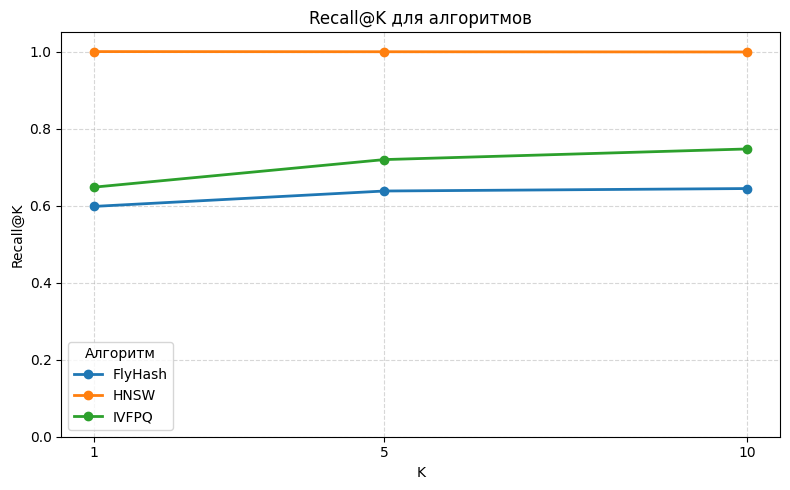

In [7]:
import matplotlib.pyplot as plt

k_values = [1, 5, 10]
recall_columns = ["Recall@1", "Recall@5", "Recall@10"]

fig, ax = plt.subplots(figsize=(8, 5))

for _, row in results_df.iterrows():
    ax.plot(
        k_values,
        [row[column] for column in recall_columns],
        marker="o",
        linewidth=2,
        label=row["Алгоритм"],
    )

ax.set(
    title="Recall@K для алгоритмов",
    xlabel="K",
    ylabel="Recall@K",
    xticks=k_values,
    ylim=(0, 1.05),
)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Алгоритм")
plt.savefig('recall_vs_k.svg')          # векторный SVG
plt.tight_layout()
plt.show()

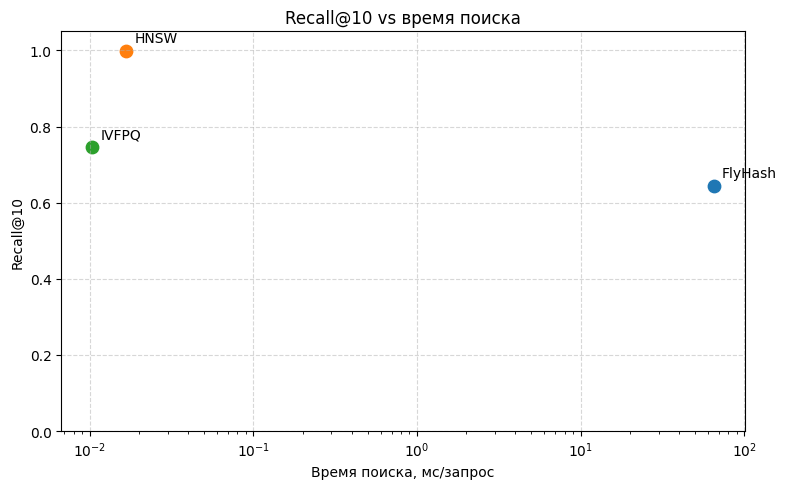

In [8]:


fig, ax = plt.subplots(figsize=(8, 5))

for _, row in results_df.iterrows():
    ax.scatter(row["Поиск, мс/запрос"], row["Recall@10"], s=80)
    ax.annotate(
        row["Алгоритм"],
        (row["Поиск, мс/запрос"], row["Recall@10"]),
        xytext=(6, 6),
        textcoords="offset points",
    )

ax.set(
    title="Recall@10 vs время поиска",
    xlabel="Время поиска, мс/запрос",
    ylabel="Recall@10",
    ylim=(0, 1.05),
)
ax.set_xscale("log")  # FlyHash ищет намного дольше, чем HNSW и IVFPQ
ax.grid(True, linestyle="--", alpha=0.5)
plt.savefig('recall_vs_time.svg')          # векторный SVG
plt.tight_layout()
plt.show()

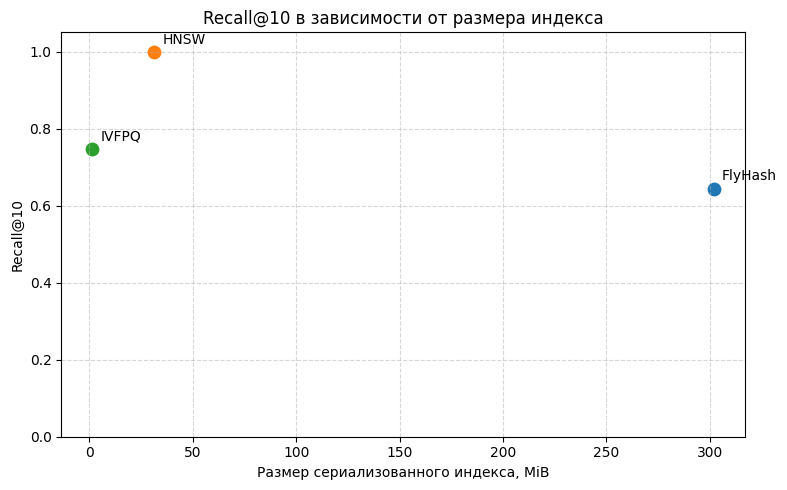

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

for _, row in results_df.iterrows():
    x = row["Размер сериализованного индекса, MiB"]
    y = row["Recall@10"]
    ax.scatter(x, y, s=80)
    ax.annotate(
        row["Алгоритм"],
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
    )

ax.set(
    title="Recall@10 в зависимости от размера индекса",
    xlabel="Размер сериализованного индекса, MiB",
    ylabel="Recall@10",
    ylim=(0, 1.05),
)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("recall_vs_memory.svg")  # Сохраняем график в векторном формате SVG.
plt.show()
